In [424]:
import pandas as pd
from pathlib import Path

current_dir = Path.cwd().resolve()

project_root = next(
    (
        p for p in [current_dir, *current_dir.parents]
        if (p / "data/processed/model_dataset.csv").exists()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "未找到 data/processed/model_dataset.csv，请检查项目目录"
    )

print("项目根目录：", project_root)

# 得到的订单级建模数据
model_data = pd.read_csv(
    project_root / "data/processed/model_dataset.csv",
    parse_dates=["order_approved_at"]
)

delivery_info = pd.read_csv(
    project_root / "data/processed/orders_with_delay.csv"
)


项目根目录： D:\各类文件\项目\olist-delivery-risk


In [425]:
# 提取并转换实际送达时间
delivery_time = delivery_info[
    ["order_id", "order_delivered_customer_date"]
].copy()

delivery_time["order_delivered_customer_date"] = pd.to_datetime(
    delivery_time["order_delivered_customer_date"]
)

# 关联到建模数据
model_data = model_data.merge(
    delivery_time,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 检查结果
print("合并后数据规模：", model_data.shape)
print("送达时间缺失数：", model_data["order_delivered_customer_date"].isna().sum())

合并后数据规模： (96372, 13)
送达时间缺失数： 0


In [426]:
# 排序仅用于计算时间边界，不改变model_data的原始顺序
sorted_time = model_data["order_approved_at"].sort_values().reset_index(drop=True)

n = len(sorted_time)

# 按70%、15%、15%划分
val_start = sorted_time.iloc[int(n * 0.70)]
test_start = sorted_time.iloc[int(n * 0.85)]

print("验证集起始时间：", val_start)
print("测试集起始时间：", test_start)
# 按时间划分数据
train = model_data[
    model_data["order_approved_at"] < val_start
].copy()

val = model_data[
    (model_data["order_approved_at"] >= val_start) &
    (model_data["order_approved_at"] < test_start)
].copy()

test = model_data[
    model_data["order_approved_at"] >= test_start
].copy()

# 只使用划分边界前已经送达的订单，避免未来标签泄漏
train_final = train[
    train["order_delivered_customer_date"] < val_start
].copy()

val_final = val[
    val["order_delivered_customer_date"] < test_start
].copy()

test_final = test.copy()

print("\n训练集：", len(train_final))
print("验证集：", len(val_final))
print("测试集：", len(test_final))

print("\n训练集延迟率：", train_final["is_delayed"].mean())
print("验证集延迟率：", val_final["is_delayed"].mean())

验证集起始时间： 2018-04-16 02:15:08
测试集起始时间： 2018-06-21 09:59:08

训练集： 64381
验证集： 12544
测试集： 14456

训练集延迟率： 0.06815675432192728
验证集延迟率： 0.04296875


In [427]:
# 7个数值特征
numeric_features = [
    "purchase_month",
    "purchase_weekday",
    "purchase_hour",
    "approval_hour",
    "item_count",
    "product_amount",
    "freight_amount"
]

# 2个类别特征
categorical_features = [
    "customer_state",
    "customer_city"
]

# 合并为9个模型特征
model_features = numeric_features + categorical_features

# 提取训练集和验证集的特征X与标签y
X_train = train_final[model_features].copy()
X_val = val_final[model_features].copy()

y_train = train_final["is_delayed"].copy()
y_val = val_final["is_delayed"].copy()

# 检查数据规模及缺失值
print("训练集特征：", X_train.shape)
print("验证集特征：", X_val.shape)

print("\n训练集缺失值：")
print(X_train.isna().sum())

print("\n训练集标签分布：")
print(y_train.value_counts())

训练集特征： (64381, 9)
验证集特征： (12544, 9)

训练集缺失值：
purchase_month      0
purchase_weekday    0
purchase_hour       0
approval_hour       0
item_count          0
product_amount      0
freight_amount      0
customer_state      0
customer_city       0
dtype: int64

训练集标签分布：
is_delayed
0    59993
1     4388
Name: count, dtype: int64


In [428]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 数值特征直接保留，类别特征使用One-Hot编码
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ), categorical_features)
    ],
    sparse_threshold=1.0
)

# 只在训练集上学习编码规则，验证集使用相同规则
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)

# 检查编码后的数据
print("训练集编码后：", X_train_processed.shape)
print("验证集编码后：", X_val_processed.shape)
print("训练集数据类型：", type(X_train_processed))

训练集编码后： (64381, 3710)
验证集编码后： (12544, 3710)
训练集数据类型： <class 'scipy.sparse._csr.csr_matrix'>


In [429]:
from sklearn.ensemble import RandomForestClassifier

# 创建随机森林分类模型
rf_model = RandomForestClassifier(
    n_estimators=120,       # 使用120棵决策树
    max_depth=16,           # 每棵树的最大深度为16
    min_samples_leaf=10,    # 每个叶节点至少包含10个样本
    max_features="sqrt",    # 每次分裂随机选择部分特征
    random_state=42,        # 固定随机种子，保证结果可复现
    n_jobs=-1               # 使用所有可用CPU核心
)

# 使用训练集训练模型
rf_model.fit(X_train_processed, y_train)

# 检查训练结果
print("随机森林训练完成！")
print("决策树数量：", len(rf_model.estimators_))
print("类别标签：", rf_model.classes_)

随机森林训练完成！
决策树数量： 120
类别标签： [0 1]


In [430]:
from sklearn.metrics import average_precision_score

# 预测验证集中每笔订单的延迟概率
# predict_proba返回两列，分别对应类别0和类别1
rf_prob = rf_model.predict_proba(X_val_processed)[:, 1]

# 计算平均精确率（AP）
rf_ap = average_precision_score(y_val, rf_prob)

# 查看预测结果
print("验证集 AP：", rf_ap)
print("预测概率最小值：", rf_prob.min())
print("预测概率最大值：", rf_prob.max())

print("\n前10笔订单的预测延迟概率：")
print(rf_prob[:10])

验证集 AP： 0.06974247584761423
预测概率最小值： 0.044114553502493596
预测概率最大值： 0.15680983502354087

前10笔订单的预测延迟概率：
[0.0611862  0.08034472 0.04817931 0.0713882  0.07439105 0.04962629
 0.07851995 0.0472583  0.06359274 0.0510368 ]


加入物流相关特征的随机森林模型，不再考虑具体城市

In [431]:
# 提取预计送达日期
estimated_info = delivery_info[
    ["order_id", "order_estimated_delivery_date"]
].copy()

estimated_info["order_estimated_delivery_date"] = pd.to_datetime(
    estimated_info["order_estimated_delivery_date"]
)

# 合并到建模数据，保持原来的订单顺序
model_data = model_data.drop(
    columns=["order_estimated_delivery_date", "promised_days"],
    errors="ignore"
)

model_data = model_data.merge(
    estimated_info,
    on="order_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# 计算预计配送天数，按日历日期计算
model_data["promised_days"] = (
    model_data["order_estimated_delivery_date"].dt.normalize()
    - model_data["order_approved_at"].dt.normalize()
).dt.days

# 检查新特征
print("数据规模：", model_data.shape)
print("\n预计配送天数统计：")
print(model_data["promised_days"].describe())

print("\n缺失值：", model_data["promised_days"].isna().sum())
print("负数数量：", (model_data["promised_days"] < 0).sum())

数据规模： (96372, 15)

预计配送天数统计：
count    96372.000000
mean        23.865936
std          8.763675
min         -1.000000
25%         18.000000
50%         23.000000
75%         29.000000
max        154.000000
Name: promised_days, dtype: float64

缺失值： 0
负数数量： 1


In [432]:
# 找出预计配送天数为负数的订单
negative_orders = model_data[
    model_data["promised_days"] < 0
]


# 查看异常订单的完整时间信息
display(
    delivery_info.loc[
        delivery_info["order_id"].isin(negative_orders["order_id"]),
        [
            "order_id",
            "order_purchase_timestamp",
            "order_approved_at",
            "order_estimated_delivery_date",
            "order_delivered_customer_date"
        ]
    ]
)

,order_id,order_purchase_timestamp,order_approved_at,order_estimated_delivery_date,order_delivered_customer_date
53698,9675440ebf61a1a3482cc6308e3ebd28,2018-08-18 23:35:23,2018-08-24 22:05:08,2018-08-23,2018-08-28 17:37:30


In [433]:
# 读取订单与卖家的对应关系
order_items = pd.read_csv(
    project_root / "data/raw/olist_order_items_dataset.csv",
    usecols=["order_id", "seller_id"]
)

# 统计每笔订单涉及的不同卖家数量
seller_counts = order_items.groupby("order_id")["seller_id"].nunique()

print("订单商品记录数：", len(order_items))
print("不同卖家数量：", order_items["seller_id"].nunique())
print("涉及多个卖家的订单数：", (seller_counts > 1).sum())
print("单笔订单最多涉及卖家数：", seller_counts.max())

订单商品记录数： 112650
不同卖家数量： 3095
涉及多个卖家的订单数： 1278
单笔订单最多涉及卖家数： 5


In [434]:
# 去重：同一订单购买同一卖家的多件商品，只算一笔历史订单
seller_orders = order_items[
    ["order_id", "seller_id"]
].drop_duplicates().copy()

# 关联历史订单的时间和延迟结果
seller_history = seller_orders.merge(
    model_data[
        [
            "order_id",
            "order_approved_at",
            "order_delivered_customer_date",
            "is_delayed"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# 检查结果
print("订单-卖家对应关系数：", len(seller_orders))
print("有效历史订单-卖家记录数：", len(seller_history))
print("历史数据中的卖家数量：", seller_history["seller_id"].nunique())

display(seller_history.head())

订单-卖家对应关系数： 100010
有效历史订单-卖家记录数： 97692
历史数据中的卖家数量： 2968


,order_id,seller_id,order_approved_at,order_delivered_customer_date,is_delayed
0,00010242fe8c5a6d1ba2dd792cb16214,48436dade18ac8b2bce089ec2a041202,2017-09-13 09:45:35,2017-09-20 23:43:48,0
1,00018f77f2f0320c557190d7a144bdd3,dd7ddc04e1b6c2c614352b383efe2d36,2017-04-26 11:05:13,2017-05-12 16:04:24,0
2,000229ec398224ef6ca0657da4fc703e,5b51032eddd242adc84c38acab88f23d,2018-01-14 14:48:30,2018-01-22 13:19:16,0
3,00024acbcdf0a6daa1e931b038114c75,9d7a1d34a5052409006425275ba1c2b4,2018-08-08 10:10:18,2018-08-14 13:32:39,0
4,00042b26cf59d7ce69dfabb4e55b4fd9,df560393f3a51e74553ab94004ba5c87,2017-02-04 14:10:13,2017-03-01 16:42:31,0


In [435]:
# 按卖家和实际送达时间排序
seller_history = seller_history.sort_values(
    ["seller_id", "order_delivered_customer_date", "order_id"]
).copy()

# 计算每个卖家截至每次历史送达时的累计订单数
seller_history["hist_order_count"] = (
    seller_history.groupby("seller_id").cumcount() + 1
)

# 计算每个卖家截至每次历史送达时的累计延迟订单数
seller_history["hist_delayed_count"] = (
    seller_history.groupby("seller_id")["is_delayed"].cumsum()
)

# 查看计算结果
display(
    seller_history[
        [
            "seller_id",
            "order_delivered_customer_date",
            "is_delayed",
            "hist_order_count",
            "hist_delayed_count"
        ]
    ].head(10)
)

,seller_id,order_delivered_customer_date,is_delayed,hist_order_count,hist_delayed_count
81233,0015a82c2db000af6aaaf3ae2ecb0532,2017-10-07 16:12:47,0,1,0
59867,0015a82c2db000af6aaaf3ae2ecb0532,2017-10-24 20:17:44,0,2,0
48472,0015a82c2db000af6aaaf3ae2ecb0532,2017-10-27 16:46:05,0,3,0
89784,001cca7ae9ae17fb1caed9dfb1094831,2017-02-23 09:23:57,0,1,0
23012,001cca7ae9ae17fb1caed9dfb1094831,2017-03-06 08:28:57,0,2,0
39267,001cca7ae9ae17fb1caed9dfb1094831,2017-03-07 16:27:44,0,3,0
52621,001cca7ae9ae17fb1caed9dfb1094831,2017-03-13 12:42:27,0,4,0
66439,001cca7ae9ae17fb1caed9dfb1094831,2017-03-14 11:08:56,0,5,0
77145,001cca7ae9ae17fb1caed9dfb1094831,2017-03-15 16:35:37,0,6,0
36821,001cca7ae9ae17fb1caed9dfb1094831,2017-03-18 05:12:32,0,7,0


In [436]:
# 获取每笔订单对应的卖家及获批时间
seller_targets = seller_orders.merge(
    model_data[["order_id", "order_approved_at"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

# 准备卖家历史累计记录
history_stats = seller_history[
    [
        "seller_id",
        "order_delivered_customer_date",
        "hist_order_count",
        "hist_delayed_count"
    ]
].copy()

# merge_asof要求按匹配时间全局排序
seller_targets = seller_targets.sort_values("order_approved_at")
history_stats = history_stats.sort_values("order_delivered_customer_date")

# 只匹配当前订单获批前已经完成的历史订单
seller_features = pd.merge_asof(
    seller_targets,
    history_stats,
    left_on="order_approved_at",
    right_on="order_delivered_customer_date",
    by="seller_id",
    direction="backward",
    allow_exact_matches=False
)

# 没有历史订单的卖家，累计数量设为0
seller_features["hist_order_count"] = (
    seller_features["hist_order_count"].fillna(0).astype(int)
)

seller_features["hist_delayed_count"] = (
    seller_features["hist_delayed_count"].fillna(0).astype(int)
)

# 计算卖家历史延迟率
seller_features["seller_hist_delay_rate"] = (
    seller_features["hist_delayed_count"]
    / seller_features["hist_order_count"].replace(0, float("nan"))
).fillna(0)

# 检查匹配结果
print("订单-卖家记录数：", len(seller_features))
print("没有历史订单的记录数：",
      (seller_features["hist_order_count"] == 0).sum())

print("是否存在使用未来数据的情况：",
      (
          seller_features["order_delivered_customer_date"]
          >= seller_features["order_approved_at"]
      ).any()
)

订单-卖家记录数： 97692
没有历史订单的记录数： 5187
是否存在使用未来数据的情况： False


In [437]:
# 按订单汇总所有卖家的历史记录
seller_order_features = seller_features.groupby(
    "order_id", as_index=False
).agg(
    seller_hist_order_count=("hist_order_count", "sum"),
    seller_hist_delayed_count=("hist_delayed_count", "sum")
)

# 计算订单对应的卖家历史延迟率
seller_order_features["seller_hist_delay_rate"] = (
    seller_order_features["seller_hist_delayed_count"]
    / seller_order_features["seller_hist_order_count"].replace(0, float("nan"))
).fillna(0)

# 检查聚合结果
print("聚合后订单数：", len(seller_order_features))
print("订单ID是否唯一：", seller_order_features["order_id"].is_unique)

print("\n卖家历史延迟率统计：")
print(seller_order_features["seller_hist_delay_rate"].describe())

print("\n无历史订单的订单数：",
      (seller_order_features["seller_hist_order_count"] == 0).sum())

display(seller_order_features.head())

聚合后订单数： 96372
订单ID是否唯一： True

卖家历史延迟率统计：
count    96372.000000
mean         0.041729
std          0.062704
min          0.000000
25%          0.000000
50%          0.028571
75%          0.058824
max          1.000000
Name: seller_hist_delay_rate, dtype: float64

无历史订单的订单数： 5053


,order_id,seller_hist_order_count,seller_hist_delayed_count,seller_hist_delay_rate
0,00010242fe8c5a6d1ba2dd792cb16214,74,1,0.013514
1,00018f77f2f0320c557190d7a144bdd3,0,0,0.000000
2,000229ec398224ef6ca0657da4fc703e,4,0,0.000000
3,00024acbcdf0a6daa1e931b038114c75,10,1,0.100000
4,00042b26cf59d7ce69dfabb4e55b4fd9,2,0,0.000000


In [438]:
# 提取需要加入模型的卖家历史特征
new_seller_features = seller_order_features[
    [
        "order_id",
        "seller_hist_delay_rate",
        "seller_hist_order_count"
    ]
].copy()

# 合并之前先清除可能存在的同名字段，避免重复运行产生冲突
model_data = model_data.drop(
    columns=["seller_hist_delay_rate", "seller_hist_order_count"],
    errors="ignore"
)

# 按订单ID合并，保持一行一订单
model_data = model_data.merge(
    new_seller_features,
    on="order_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# 检查合并结果
print("合并后数据规模：", model_data.shape)

print("\n新增特征缺失值：")
print(model_data[
    [
        "promised_days",
        "seller_hist_delay_rate",
        "seller_hist_order_count"
    ]
].isna().sum())

print("\n新增特征统计：")
display(model_data[
    [
        "promised_days",
        "seller_hist_delay_rate",
        "seller_hist_order_count"
    ]
].describe())

合并后数据规模： (96372, 17)

新增特征缺失值：
promised_days              0
seller_hist_delay_rate     0
seller_hist_order_count    0
dtype: int64

新增特征统计：


,promised_days,seller_hist_delay_rate,seller_hist_order_count
count,96372.000000,96372.000000,96372.000000
mean,23.865936,0.041729,173.360582
std,8.763675,0.062704,288.947671
min,-1.000000,0.000000,0.000000
25%,18.000000,0.000000,12.000000
50%,23.000000,0.028571,53.000000
75%,29.000000,0.058824,185.000000
max,154.000000,1.000000,2617.000000


In [439]:
# 定义数值特征（10个）
numeric_features_new = [
    "purchase_month",
    "purchase_weekday",
    "purchase_hour",
    "approval_hour",
    "item_count",
    #"product_amount",
    "freight_amount",
    "promised_days",
    #"seller_hist_delay_rate",
    #"seller_hist_order_count"
]

# 定义类别特征（1个，不再使用城市）
categorical_features_new = ["customer_state"]

model_features_new = numeric_features_new + categorical_features_new

# 按之前计算的时间边界重新划分，并检查标签可用性
train_new = model_data[
    (model_data["order_approved_at"] < val_start) &
    (model_data["order_delivered_customer_date"] < val_start)
].copy()

val_new = model_data[
    (model_data["order_approved_at"] >= val_start) &
    (model_data["order_approved_at"] < test_start) &
    (model_data["order_delivered_customer_date"] < test_start)
].copy()

test_new = model_data[
    model_data["order_approved_at"] >= test_start
].copy()

# 提取模型输入特征和延迟标签
X_train_new = train_new[model_features_new].copy()
X_val_new = val_new[model_features_new].copy()

y_train_new = train_new["is_delayed"].copy()
y_val_new = val_new["is_delayed"].copy()

# 检查数据
print("训练集：", X_train_new.shape)
print("验证集：", X_val_new.shape)
print("测试集订单数：", len(test_new))

print("\n特征列表：")
print(model_features_new)

print("\n特征缺失值总数：",
      X_train_new.isna().sum().sum() + X_val_new.isna().sum().sum())

训练集： (64381, 8)
验证集： (12544, 8)
测试集订单数： 14456

特征列表：
['purchase_month', 'purchase_weekday', 'purchase_hour', 'approval_hour', 'item_count', 'freight_amount', 'promised_days', 'customer_state']

特征缺失值总数： 0


In [440]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 构建新模型的特征预处理器
preprocessor_new = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features_new),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        ), categorical_features_new)
    ],
    sparse_threshold=1.0
)

# 只在训练集上拟合，验证集使用相同编码规则
X_train_processed_new = preprocessor_new.fit_transform(X_train_new)
X_val_processed_new = preprocessor_new.transform(X_val_new)

# 检查编码结果
print("训练集编码后：", X_train_processed_new.shape)
print("验证集编码后：", X_val_processed_new.shape)
print("数据类型：", type(X_train_processed_new))

训练集编码后： (64381, 34)
验证集编码后： (12544, 34)
数据类型： <class 'scipy.sparse._csr.csr_matrix'>


In [441]:
from sklearn.ensemble import RandomForestClassifier

# 创建新的随机森林模型，参数与原模型一致
rf_model_new = RandomForestClassifier(
    n_estimators=120,       # 120棵决策树
    max_depth=10,           # 最大树深度
    min_samples_leaf=30,    # 叶节点最少样本数
    max_features="sqrt",    # 每次分裂随机选择部分特征
    random_state=42,        # 固定随机种子
    n_jobs=-1               # 并行训练
)

# 使用11个新特征训练模型
rf_model_new.fit(X_train_processed_new, y_train_new)

print("新随机森林训练完成！")
print("决策树数量：", len(rf_model_new.estimators_))
print("模型输入特征数：", rf_model_new.n_features_in_)

新随机森林训练完成！
决策树数量： 120
模型输入特征数： 34


In [442]:
from sklearn.metrics import average_precision_score

# 预测验证集订单的延迟概率
rf_prob_new = rf_model_new.predict_proba(
    X_val_processed_new
)[:, 1]

# 计算AP
rf_ap_new = average_precision_score(
    y_val_new, rf_prob_new
)

print("验证集 AP：", rf_ap_new)
print("预测概率最小值：", rf_prob_new.min())
print("预测概率最大值：", rf_prob_new.max())

验证集 AP： 0.11372168646059282
预测概率最小值： 0.019819493480234936
预测概率最大值： 0.2180666579854624


In [443]:
# 预测训练集的延迟概率
rf_train_prob_new = rf_model_new.predict_proba(
    X_train_processed_new
)[:, 1]

# 计算训练集AP
rf_train_ap_new = average_precision_score(
    y_train_new, rf_train_prob_new
)

print("训练集 AP：", rf_train_ap_new)
print("验证集 AP：", rf_ap_new)

训练集 AP： 0.23695454855187267
验证集 AP： 0.11372168646059282


In [444]:
import joblib

# 创建模型保存目录
model_dir = project_root / "models"
model_dir.mkdir(parents=True, exist_ok=True)

# 保存模型及其预处理配置
model_bundle = {
    "model": rf_model_new,
    "preprocessor": preprocessor_new,
    "features": model_features_new,
    "numeric_features": numeric_features_new,
    "categorical_features": categorical_features_new,
    "val_start": val_start,
    "test_start": test_start,
    "label_rule": "calendar_date",
    "validation_ap": rf_ap_new
}

# 保存当前版本，避免以后调整模型时覆盖
model_path = model_dir / "random_forest_v1.joblib"

joblib.dump(model_bundle, model_path)

print("模型保存成功：", model_path)
print("文件大小：", round(model_path.stat().st_size / 1024**2, 2), "MB")

模型保存成功： D:\各类文件\项目\olist-delivery-risk\models\random_forest_v1.joblib
文件大小： 3.01 MB


测试集

In [445]:
# 提取测试集特征和标签
X_test_new = test_new[model_features_new].copy()
y_test_new = test_new["is_delayed"].copy()

# 使用训练好的预处理器转换测试集
X_test_processed_new = preprocessor_new.transform(X_test_new)

# 预测测试集订单延迟概率
rf_test_prob = rf_model_new.predict_proba(
    X_test_processed_new
)[:, 1]

# 计算测试集AP
test_ap = average_precision_score(
    y_test_new, rf_test_prob
)

print("测试集订单数：", len(y_test_new))
print("测试集延迟率：", y_test_new.mean())
print("测试集 AP：", test_ap)

测试集订单数： 14456
测试集延迟率： 0.04281959048146099
测试集 AP： 0.08481318717604068


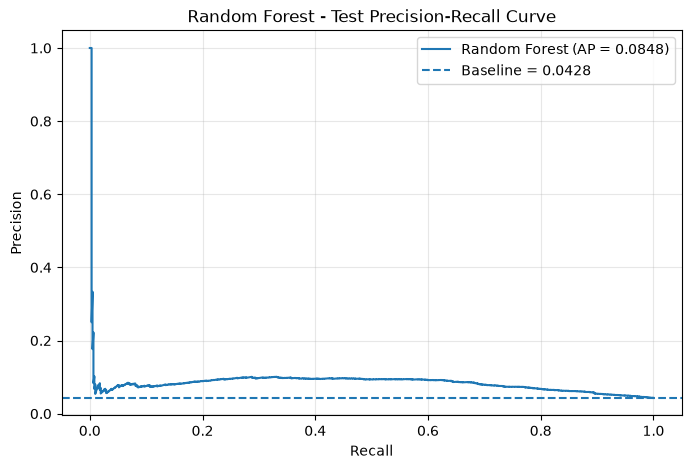

In [446]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

# 计算测试集PR曲线
precision, recall, _ = precision_recall_curve(
    y_test_new,
    rf_test_prob
)

# 绘制PR曲线
plt.figure(figsize=(8, 5))

plt.plot(
    recall,
    precision,
    label=f"Random Forest (AP = {test_ap:.4f})"
)

# 随机预测基线为测试集延迟率
plt.axhline(
    y=y_test_new.mean(),
    linestyle="--",
    label=f"Baseline = {y_test_new.mean():.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Test Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [447]:
from sklearn.inspection import permutation_importance
from sklearn.pipeline import Pipeline

# 组合已经训练好的预处理器和随机森林
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor_new),
    ("model", rf_model_new)
])

# 在验证集上计算置换特征重要性
importance = permutation_importance(
    rf_pipeline,
    X_val_new,
    y_val_new,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# 整理结果
importance_df = pd.DataFrame({
    "feature": model_features_new,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df)

,feature,importance_mean,importance_std
7,customer_state,5.752849e-02,0.001148
6,promised_days,3.572077e-02,0.001219
5,freight_amount,9.557850e-03,0.003800
4,item_count,1.760547e-03,0.000582
2,purchase_hour,3.536163e-04,0.000530
0,purchase_month,-1.713877e-07,0.000502
1,purchase_weekday,-8.441355e-04,0.000514
3,approval_hour,-1.709541e-03,0.001260


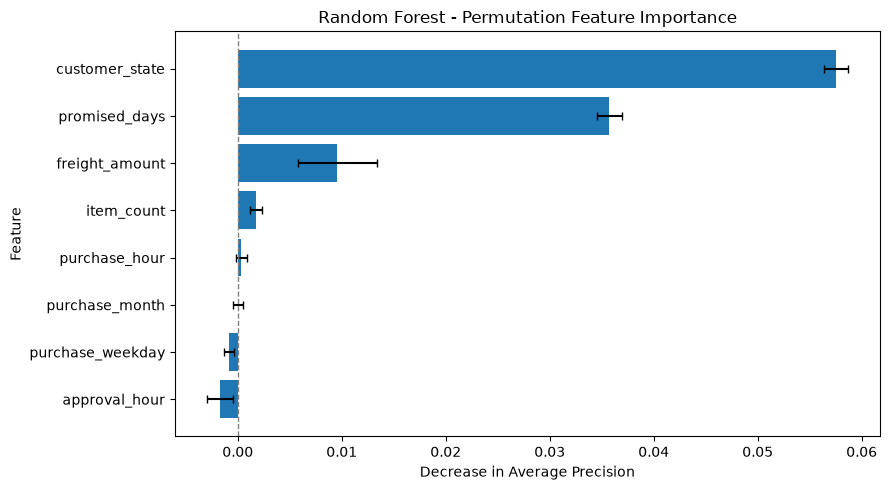

In [448]:
import matplotlib.pyplot as plt

# 按重要性从小到大排序，方便绘制水平柱状图
plot_df = importance_df.sort_values("importance_mean")

plt.figure(figsize=(9, 5))

plt.barh(
    plot_df["feature"],
    plot_df["importance_mean"],
    xerr=plot_df["importance_std"],
    capsize=3
)

# 标记重要性为0的位置
plt.axvline(0, color="gray", linestyle="--", linewidth=1)

plt.xlabel("Decrease in Average Precision")
plt.ylabel("Feature")
plt.title("Random Forest - Permutation Feature Importance")

plt.tight_layout()
plt.show()

In [449]:
import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score
)

# 在验证集上寻找F1最高的分类阈值
precision, recall, thresholds = precision_recall_curve(
    y_val_new, rf_prob_new
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_threshold = thresholds[np.argmax(f1_scores)]

# 使用同一个阈值进行预测
val_pred = (rf_prob_new >= best_threshold).astype(int)
test_pred = (rf_test_prob >= best_threshold).astype(int)

# 输出评估结果
print("分类阈值：", best_threshold)

for name, y_true, y_pred in [
    ("验证集", y_val_new, val_pred),
    ("测试集", y_test_new, test_pred)
]:
    print(f"\n{name}：")
    print("Precision：", precision_score(y_true, y_pred, zero_division=0))
    print("Recall：", recall_score(y_true, y_pred, zero_division=0))
    print("F1-score：", f1_score(y_true, y_pred, zero_division=0))

分类阈值： 0.07474177791499796

验证集：
Precision： 0.15346534653465346
Recall： 0.287569573283859
F1-score： 0.2001291155584248

测试集：
Precision： 0.0961862976712791
Recall： 0.4604200323101777
F1-score： 0.15912897822445563


# 随机森林订单延迟预测实验总结

## 1. 实验目标与数据划分

使用随机森林（Random Forest）预测电商订单是否延迟送达。

延迟标签 `is_delayed` 按日历日期定义：实际送达日期晚于预计送达日期记为 1，否则记为 0。

数据按照订单获批时间划分，并排除在相应划分时点尚未送达、无法观察延迟标签的训练和验证订单。

| 数据集 | 样本数量 | 延迟率 |
|---|---:|---:|
| 训练集 | 64,381 | 6.82% |
| 验证集 | 12,544 | 4.30% |
| 测试集 | 14,456 | 4.28% |

## 2. 特征工程与模型优化

在原始订单时间、金额、商品数量和地区特征的基础上，进一步构造：

- `promised_days`：订单获批时距离预计送达日期的天数。
- `seller_hist_delay_rate`：卖家历史已完成订单的延迟率。
- `seller_hist_order_count`：卖家历史已完成订单数量。

卖家历史特征仅使用当前订单获批之前已经送达的订单，避免未来信息泄漏。

通过特征消融实验比较不同特征组合：

| 模型配置 | 验证集 AP |
|---|---:|
| 原始 9 特征随机森林 | 0.069742 |
| 增加预计配送时长 | 0.111274 |
| 预计配送时长 + 卖家历史延迟率 | 0.108493 |
| 预计配送时长 + 卖家历史订单数 | 0.088290 |
| 三个新增特征全部加入 | 0.093244 |

实验表明，**预计配送时长对预测效果提升最明显**，而当前构造的卖家历史特征没有带来额外改善。

随后进一步调整特征组合和随机森林复杂度。

## 3. 最终模型

最终采用 8 个特征：

`purchase_month`、`purchase_weekday`、`purchase_hour`、`approval_hour`、`item_count`、`freight_amount`、`promised_days`、`customer_state`。

随机森林主要参数：

| 参数 | 数值 |
|---|---:|
| `n_estimators` | 120 |
| `max_depth` | 10 |
| `min_samples_leaf` | 30 |
| `max_features` | sqrt |
| `random_state` | 42 |

最终评估结果：

| 指标 | AP |
|---|---:|
| 训练集 | 0.236955 |
| 验证集 | **0.113722** |
| 测试集 | **0.084813** |

测试集 AP 为 8.48%，约为测试集延迟率基线（4.28%）的 1.98 倍，说明模型具有一定的延迟风险排序能力，但预测性能仍然有限。

最终模型保存于 `models/random_forest_v1.joblib`。

## 4. 模型解释与可视化

在独立测试集上绘制 PR 曲线，并在验证集上计算置换特征重要性（Permutation Importance）。

主要结果：

| 特征 | 置换后 AP 平均下降 |
|---|---:|
| `customer_state` | 0.057528 |
| `promised_days` | 0.035721 |
| `freight_amount` | 0.009558 |
| `item_count` | 0.001761 |

模型主要依赖**客户所在州和预计配送时长**进行风险预测。特征重要性反映模型的预测依赖程度，不代表因果关系。

## 5. 实验结论

本实验完成了随机森林训练、业务特征构造、特征消融、参数调整、模型保存及独立测试集评估。

**最终测试集 AP 为 0.084813，高于随机排序基线。**

实验说明，增加具有业务意义的预计配送时长特征能够改善订单延迟预测效果，但模型仍存在泛化性能有限、类别不平衡等问题。

此外，训练和验证样本的送达时间筛选可能带来选择偏差；使用预计配送日期还需要假设该信息在订单获批时已经可知。

因此，当前模型可作为订单延迟风险分析的实验模型，尚不能直接用于实际业务预警。